# 3. Do it yourself

Use the GMV tutorial as your guide. This time the features come from EEG.

Data: Hernandez et al. (2024), *Brain health in diverse settings: How age, demographics and cognition shape brain function*, NeuroImage.

Repository: https://github.com/euroladbrainlat/Brain-health-in-diverse-setting

Table: `aperiodic_total_sample.xlsx`.

The supplied table contains 1,286 rows, 10 regional aperiodic features (well, only the aperiodic slope), Age, Sex and Educ.

The paper's full sample is larger; use the actual rows in this table.

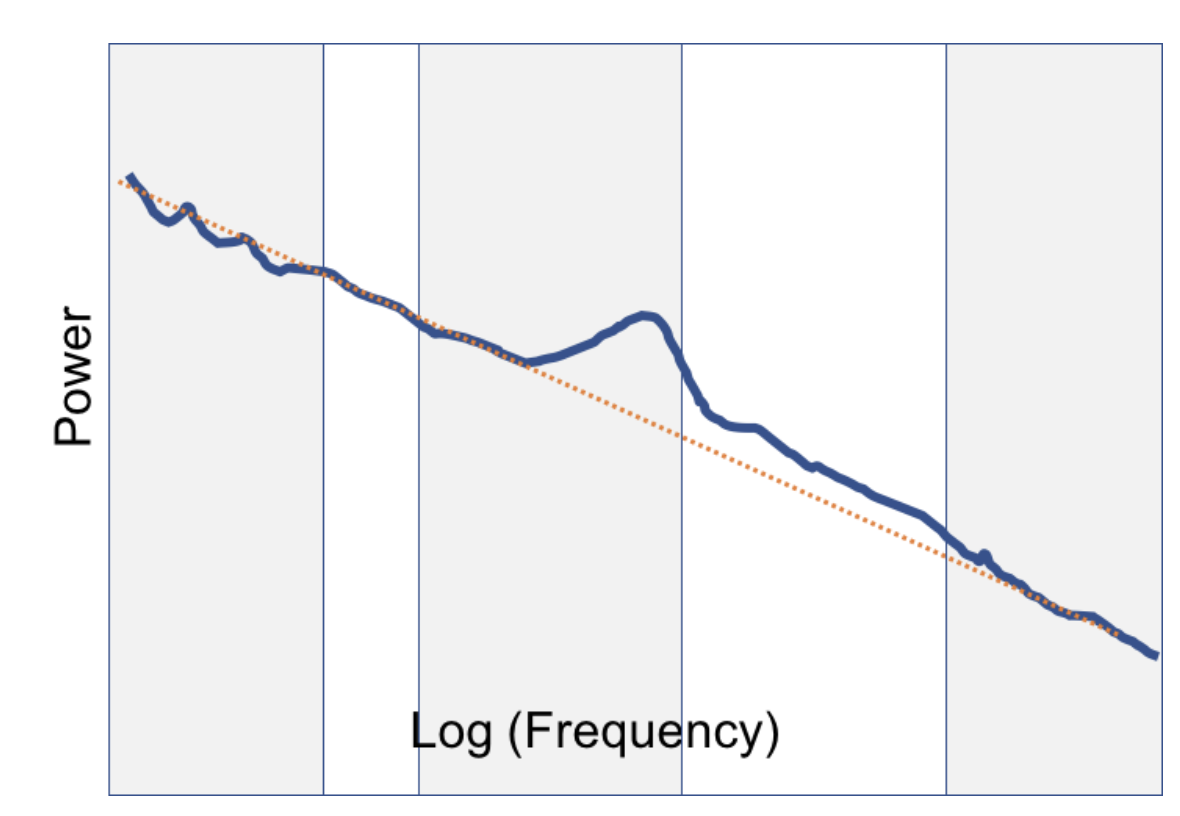

**Source:** sapienlabs.org

More context (from Sapien Labs):

"One way to think about this is that it provides a reflection of the relative proportion of higher frequencies to lower frequencies and is therefore a metric of the spectral energy of the system. A shallower decay or slope means a relatively higher ratio of high to low frequencies than a steeper slope and therefore higher spectral energy in the signal."

Some works related the aperiodic exponent to aging, dementia, and E/I balance:

- https://www.nature.com/articles/s41598-023-47316-0
- https://www.nature.com/articles/s41467-025-62798-4.pdf


## Your question
Can a model trained on EEG features predict age? Are its held-out BAGs associated with education after controlling for age?

Use only the Aperiodic Slope. Age is the target. Educ, Sex and the exported index are not brain features.
Keep education out of model training, tuning and age-bias correction.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "aperiodic_total_sample.xlsx").exists():
    ROOT = ROOT.parent
raw = pd.read_excel(ROOT / "aperiodic_total_sample.xlsx")
feature_columns = [c for c in raw if c.startswith(("Slope_"))]
display(raw[["Age", "Educ", "Sex"]].describe())
print("Rows:", len(raw), "Brain features:", len(feature_columns))


,Age,Educ,Sex
count,1285.000000,1285.000000,1285.000000
mean,46.522698,13.758366,1.540078
std,20.796311,4.265637,0.498585
min,18.000000,0.000000,1.000000
25%,25.000000,11.000000,1.000000
50%,48.000000,15.000000,2.000000
75%,66.000000,16.000000,2.000000
max,91.000000,28.000000,2.000000


Rows: 1285 Brain features: 10


## Check the data
Inspect missing values, age range and unusual feature values.

In [7]:
# TO-DO: inspect the data and make an analysis copy.

## Train and evaluate

Build a linear SVR. 

Use 5 folds repeated 10 times, with seed 1234 (or anything else).

**Start with fixed settings, such as C = 1 and epsilon = 3** (easier and faster for a first exploration). If you tune them, keep tuning inside the outer training data.

Report held-out MAE, R2 and the age-prediction correlation. Fit preprocessing inside each training fold.

Every participant should have one test prediction per repetition.


In [6]:
N_SPLITS = 5
N_REPEATS = 10
SEED = 1234
# TO-DO: create the pipeline, CV splits and held-out predictions.


## Compute BAGs
Compute `BAG = predicted age - age` from test predictions only.
Average the ten held-out predictions within each participant. 

Plot BAG against age. For the corrected version, estimate the age-bias adjustment using only each outer training set and apply it unchanged to that fold's test participants.

Use the training-only calibration procedure from notebook 2.

In [4]:
# TO-DO: calculate raw and corrected BAGs, then inspect their age correlations.

## Education: choose one route, or try both
**Continuous:** test the association between BAG and Educ while controlling for Age. You can use partial correlation or a regression with both predictors.

**Groups:** compute the 33rd and 66th percentiles of Educ. Low education = at or below P33; high education = at or above P66.
Leave the middle group out of this comparison, but keep everyone in clock training and evaluation.
Keep ties together and report the cutoffs and group sizes. Compare BAGs while controlling for age; check whether group slopes differ.

Use education values from 0 to 30 years for the association and percentile cutoffs. Report how many values were excluded.

In [8]:
# TO-DO: analyse BAG versus education, controlling for age.

## Prefer your own data?
You may use your own dataset if you have something in hand.
